# TP 4c — La carte et le spectre (corrigé)
On repart du DataFrame interpolé du TP 4b : les deux premières cellules le reconstruisent.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import fft, stats
from scipy.spatial import KDTree

DONNEES = "../donnees/"
m = pd.read_csv(DONNEES + "mesures.csv", parse_dates=["horodatage"])
m["no2"] = m.groupby("capteur")["no2"].transform(
    lambda s: s.interpolate(limit_direction="both"))
cap = pd.read_sql("SELECT id, nom, quartier, lat, lon FROM capteurs",
                  sqlite3.connect(DONNEES + "capteurs.db"))

## 1. Tester le week-end : test t de Welch

In [2]:
we = m["horodatage"].dt.dayofweek >= 5
r = stats.ttest_ind(m.loc[~we, "no2"], m.loc[we, "no2"], equal_var=False)
print(f"Ville      t = {r.statistic:5.1f}   p = {r.pvalue:.1e}")
for q, g in m.groupby("quartier"):
    w = g["horodatage"].dt.dayofweek >= 5
    r = stats.ttest_ind(g.loc[~w, "no2"], g.loc[w, "no2"], equal_var=False)
    print(f"{q:<10} t = {r.statistic:5.1f}   p = {r.pvalue:.1e}")

Ville      t =  15.7   p = 1.7e-54
Centre     t =  10.8   p = 3.3e-26
Gare       t =  10.2   p = 7.6e-24
Port       t =   9.6   p = 2.5e-21
Université t =   8.3   p = 1.7e-16


## 2. La carte

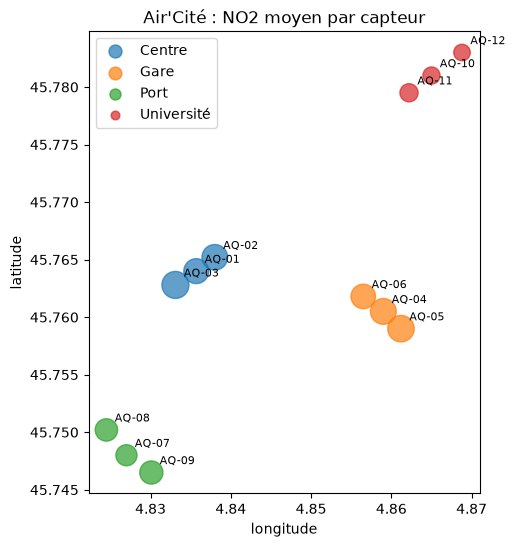

In [3]:
cap = cap.merge(m.groupby("capteur")["no2"].mean().rename("no2_moy"),
                left_on="id", right_index=True)
fig, ax = plt.subplots(figsize=(7, 6))
for q, g in cap.groupby("quartier"):
    ax.scatter(g["lon"], g["lat"], s=g["no2_moy"] * 12, label=q, alpha=.7)
for r in cap.itertuples():
    ax.annotate(r.id, (r.lon, r.lat), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.set_aspect(1 / np.cos(np.radians(45.765)))   # un degré de longitude est plus court
ax.set_title("Air'Cité : NO2 moyen par capteur")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.legend(markerscale=.5)
fig.savefig("carte.png", dpi=120, bbox_inches="tight")

## 3. Le capteur le plus proche de trois adresses

In [4]:
k = 111.32 * np.cos(np.radians(45.765))          # km par degré de longitude, ici
xy = np.c_[cap["lon"] * k, cap["lat"] * 110.57]
arbre = KDTree(xy)
adresses = {"École Jean-Moulin": (45.7620, 4.8450),
            "Crèche des Docks": (45.7495, 4.8290),
            "Gymnase du Campus": (45.7820, 4.8600)}
for nom, (lat, lon) in adresses.items():
    dist, i = arbre.query([lon * k, lat * 110.57])
    print(f"{nom:<18} → {cap.loc[i, 'id']} {cap.loc[i, 'nom']:<16} {dist:.2f} km")

École Jean-Moulin  → AQ-02 Place des Halles 0.65 km
Crèche des Docks   → AQ-07 Quai des Docks   0.23 km
Gymnase du Campus  → AQ-11 Bibliothèque     0.32 km


## 4. Le spectre de la ville

période   12.0 h   amplitude   3126
période    8.0 h   amplitude   1893
période   24.0 h   amplitude   1141
période    4.8 h   amplitude   1029
période    6.0 h   amplitude    922


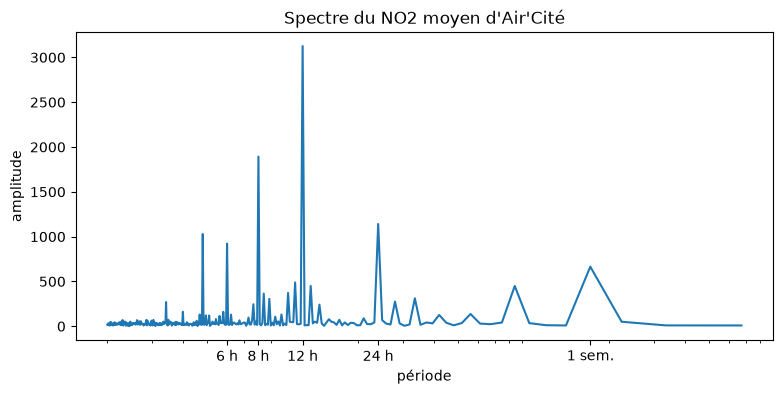

In [5]:
s = m.groupby("horodatage")["no2"].mean()
y = s.to_numpy() - s.mean()                       # centrer, sinon la fréquence nulle écrase tout
spectre = np.abs(fft.rfft(y))
freqs = fft.rfftfreq(len(y), d=1)                 # cycles par heure
periodes = 1 / freqs[1:]
amp = spectre[1:]
top = np.argsort(amp)[::-1][:5]
for j in top:
    print(f"période {periodes[j]:6.1f} h   amplitude {amp[j]:6.0f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(periodes, amp)
ax.set_xscale("log")
ax.set_xticks([6, 8, 12, 24, 168])
ax.set_xticklabels(["6 h", "8 h", "12 h", "24 h", "1 sem."])
ax.set_xlabel("période")
ax.set_ylabel("amplitude")
ax.set_title("Spectre du NO2 moyen d'Air'Cité")
fig.savefig("spectre.png", dpi=120, bbox_inches="tight")

**Le NO2 d'Air'Cité suit le rythme du trafic** : un cycle de 24 h à deux pointes
(d'où les harmoniques à 12 h, 8 h, 6 h), et un rythme hebdomadaire plus faible.

## Bonus : le spectre de la température

In [6]:
t = m.groupby("horodatage")["temp"].mean()
amp_t = np.abs(fft.rfft(t.to_numpy() - t.mean()))[1:]
for j in np.argsort(amp_t)[::-1][:4]:
    print(f"température : période {periodes[j]:6.1f} h   amplitude {amp_t[j]:6.0f}")

température : période   24.0 h   amplitude   1684
température : période  672.0 h   amplitude    429
température : période  336.0 h   amplitude    221
température : période  224.0 h   amplitude    142
